Ciao, questo in teoria è il codice che prende dati che realmente ci servono per la domanda di ricerca

Cella di preparazione, in cui importiamo ciò che ci serve:

In [ ]:
import csv #per leggere i file
import seaborn as sns #sns abbreviazione di seaborn, è soprannome
import matplotlib.pyplot as plt #plt abbreviazione di matplotlib, è soprannome

STATI = ["Siria", "Afghanistan", "Iraq", "Sudan", "Libia"] #nazionalità in analisi
ANNI = ["2003", "2014", "2015", "2016", "2025"] #anni come stringhe

def file_cittadinanza(anno):
    return f"Dati_cittadinanza_{anno}.csv" #f-string, {anno} viene sostituito con il valore passato

Cella che legge i file:

In [ ]:
def leggi_cittadinanza(anno):
    cercati = {s.lower(): s for s in STATI} #costruisce un dizionario che collega il nome in minuscolo a quello originale:
            # {"siria": "Siria", "afghanistan": "Afghanistan", "iraq": "Iraq", ...}
            #serve perchè nel file i nomi potrebbero avere minuscole o spazi diversi. il codice confronta sempre la versione minuscola, ma salva i risultati con il nome scelto da me.
    dati = {s: {"maschi": 0, "femmine": 0, "totale": 0} for s in STATI}
        # prepara per ogni stato un dizionario con tre contatori a 0:
        # {"Siria": {"maschi":0, "femmine":0, "totale":0}, "Afghanistan": {...},...}
    stranieri = 0   # totale di tutti gli stranieri, anche di stati non in analisi. Serve per le quote
    with open(file_cittadinanza(anno), newline="", encoding="utf-8") as f:
        #file_cittadinanza(anno) costruisce il nome, ad esempio "Dati_cittadinanza_2014.csv", open lo apre
        #with ... as f: apre e richiude il file da solo alla fine.
        for r in csv.DictReader(f, delimiter=";"):
            #ogni riga r è un dizionario con le intestazioni come chiavi:
            # r["Totale"], r["Stato di cittadinanza"], etc.
            if r["Codice Istat"] != "IT":      # solo la riga nazionale, evita il conteggio multiplo
            #nel file ci sono divisioni per comuni, province e regioni; tenendo conto solo di IT evito ripetizioni
            #sotto metto una cella se invece vogliamo considerare la differenza regionale, così stiamo considerando in generale l'Italia.
                continue
            nome = r["Stato di cittadinanza"].strip().lower()
            #strip toglie spazi, lower in minuscolo.
            if nome == "italia":# i cittadini italiani non sono stranieri, non devo contarli
                continue
            stranieri += int(r["Totale"]) #aggiunge il totale di questa riga al contatore di tutti gli stranieri. int perchè csv legge i numeri come testo.
            if nome in cercati: #se lo stato è tra quelli che ci interessano:
                d = dati[cercati[nome]] #ritrova nome originale => da "siria" a "Siria"
                                        #dati prende il dizionario di quello stato e lo chiama d
                d["maschi"] += int(r["Maschi"])
                d["femmine"] += int(r["Femmine"])
                d["totale"] += int(r["Totale"]) #somme ai contatori.
    return dati, stranieri #per esempio, per la Siria restituirebbe:
    #dati["Siria"] = {"maschi": 1269, "femmine": 791, "totale": 2060}, stranieri = 1483277

cittadinanza = {}      # cittadinanza[anno][stato] = {"maschi", "femmine", "totale"}
stranieri_tot = {}     # stranieri_tot[anno] = tutti gli stranieri residenti
for anno in ANNI:
    cittadinanza[anno], stranieri_tot[anno] = leggi_cittadinanza(anno)

Questa cella non legge più il file ma usa i dizionari creati nella cella sopra per calcolare le quote e stampare due tabelle:

In [ ]:
quote = {}
for a in ANNI:# a = "2003", poi "2014", ...
    quote[a] = {}
    for s in STATI:# s = "Siria", poi "Afghanistan", ...
        totale_stato = cittadinanza[a][s]["totale"]
        quote[a][s] = totale_stato / stranieri_tot[a] * 100
                    # residenti di quella cittadinanza / totale di stranieri * 100
                    #per la Siria: 2060 / 1483277 * 100 = 0,139%
                    #cioè su 100 stranieri residenti in Italia nel 2003, 0,139 avevano cittadinanza siriana.
print("Residenti con cittadinanza straniera") #titolo
print(f'{"Stato":<14}' + "".join(f"{a:>9}" for a in ANNI))
    #stato allineato a sinistra in 14 caratteri
    #"".join fa una colonna per ogni anno
    #f"{a:>9}" allinea l'anno a destra in 9 caratteri
    #"".join incolla tutte le stringhe una dopo l'altra.
for s in STATI:
    print(f"{s:<14}" + "".join(f"{cittadinanza[a][s]['totale']:>9}" for a in ANNI))
    #stampa una riga per nazionalità con il nome a sinistra e, per ogni anno, il suo totale cittadinanza[a][s]['totale'] allineato a destra.
print(f'{"Tot. stranieri":<14}' + "".join(f"{stranieri_tot[a]:>9}" for a in ANNI))
#stampa totale di stranieri per ogni anno, in fondo alla tabella.

print("\nQuota sul totale degli stranieri (%)") #\n lascia una riga vuota tra le due tabelle
print(f'{"Stato":<14}' + "".join(f"{a:>9}" for a in ANNI))
for s in STATI:
    print(f"{s:<14}" + "".join(f"{quote[a][s]:>9.3f}" for a in ANNI))
                                # stampa la quota con 3 cifre decimali (.3f), allineata a detsra in 9 caratteri. 3 decimali perchè alcune quote sono molto piccole. 

Residenti con cittadinanza straniera
Stato              2003     2014     2015     2016     2025
Siria              2060     4477     4739     4463     6896
Afghanistan         486     5750     6651     7961    17795
Iraq                928     2677     2808     2649     7938
Sudan               569     2207     2245     2169     2947
Libia              1762     1554     1741     1719     3268
Tot. stranieri  1483277  4787166  4835245  4831042  5371251

Quota sul totale degli stranieri (%)
Stato              2003     2014     2015     2016     2025
Siria             0.139    0.094    0.098    0.092    0.128
Afghanistan       0.033    0.120    0.138    0.165    0.331
Iraq              0.063    0.056    0.058    0.055    0.148
Sudan             0.038    0.046    0.046    0.045    0.055
Libia             0.119    0.032    0.036    0.036    0.061


Le quote sono importanti da inserire perchè in generale i totali assoluti crescono quasi sempre, perchè tendenzialmente gli stranieri aumentano in Italia col passare del tempo.
La quota ci dice se il peso relativo di una nazinonalità è aumentato o diminuito rispetto alle altre, ed è il dato confrontabile con la percentuale di menzioni negli articoli, che ha la stessa scala.


Sotto metto un'altra cella EQUIVALENTE ALLA 3 ma con pandas, così da avere delle tabelle più carine, poi decidiamo quale usare.

In [9]:
import pandas as pd

quote = {a: {s: cittadinanza[a][s]["totale"] / stranieri_tot[a] * 100 for s in STATI} for a in ANNI}

# tabella dei totali
tab_totali = pd.DataFrame({a: {s: cittadinanza[a][s]["totale"] for s in STATI} for a in ANNI})
tab_totali.loc["Tot. stranieri"] = [stranieri_tot[a] for a in ANNI]
tab_totali.index.name = "Stato"
tab_totali.columns.name = "Anno"

# tabella delle quote
tab_quote = pd.DataFrame(quote)
tab_quote.index.name = "Stato"
tab_quote.columns.name = "Anno"

print("Residenti con cittadinanza straniera")
display(tab_totali)

print("Quota sul totale degli stranieri (%)")
display(tab_quote.round(3))

Residenti con cittadinanza straniera


Anno,2003,2014,2015,2016,2025
Stato,,,,,
Siria,2060,4477,4739,4463,6896
Afghanistan,486,5750,6651,7961,17795
Iraq,928,2677,2808,2649,7938
Sudan,569,2207,2245,2169,2947
Libia,1762,1554,1741,1719,3268
Tot. stranieri,1483277,4787166,4835245,4831042,5371251


Quota sul totale degli stranieri (%)


Anno,2003,2014,2015,2016,2025
Stato,,,,,
Siria,0.139,0.094,0.098,0.092,0.128
Afghanistan,0.033,0.120,0.138,0.165,0.331
Iraq,0.063,0.056,0.058,0.055,0.148
Sudan,0.038,0.046,0.046,0.045,0.055
Libia,0.119,0.032,0.036,0.036,0.061


Questa cella invece confronta due anni alla volta e stampa una tabella per ogni periodo.

In [10]:
def perc(nuovo, vecchio): #calcola la variazione percentuale tra un valore vecchio e uno nuovo e la restituisce come testo
    return f"{(nuovo - vecchio) / vecchio * 100:+.1f}%" if vecchio > 0 else "n.d."
            # :+.1f mostra una cifra decimale e sempre il segno; il % dopo le graffe è solo un carattere di testo.
                                                        # se il valore di partenza è 0 la divisione è impossibile => la funzione restituisce "non disponibile".

def confronto_periodo(da, a): #riceve due anni: da, a
    anni = int(a) - int(da) #gli anni sono due stringhe, quindi vanno convertiti in interi. esempio: 2014 - 2003 = 11. lo usa la colonna diff/anno
    print(f"\n{da} -> {a} ({anni} anni)") #scrive il titolo
    print(f'{"Stato":<14}{da:>9}{a:>9}{"Diff":>9}{"Var %":>10}{"Diff/anno":>11}{"Quota (pp)":>12}') #intestazioni delle colonne
    for s in STATI:
        v1, v2 = cittadinanza[da][s]["totale"], cittadinanza[a][s]["totale"]
        #v1 e v2 sono i residenti di quella cittadinanza nell'anno vecchio e in quello recente, presi dal dizionario nella cella 2
        dq = quote[a][s] - quote[da][s] #differenza tra le due quote
        print(f"{s:<14}{v1:>9}{v2:>9}{v2 - v1:>+9}{perc(v2, v1):>10}{(v2 - v1) / anni:>+11.1f}{dq:>+12.3f}")
        #scrive la riga con 6 colonne:
        #v1 e v2 sono i totali dei due anni
        #v12 - v1 è la differenza assoluta
        #perc(v2, v1) è la variazione percentuale, è già testo
        #(v2 - v1) / anni è quante persone in più o in meno all'anno in media
        #dq è la variazione della quota, con tre decimali

confronto_periodo("2003", "2014")   # prima della crisi
confronto_periodo("2014", "2015")   #durante la crisi
confronto_periodo("2014", "2016")   # durante la crisi
confronto_periodo("2016", "2025")   # dopo
confronto_periodo("2003", "2025")   # quadro complessivo


2003 -> 2014 (11 anni)
Stato              2003     2014     Diff     Var %  Diff/anno  Quota (pp)
Siria              2060     4477    +2417   +117.3%     +219.7      -0.045
Afghanistan         486     5750    +5264  +1083.1%     +478.5      +0.087
Iraq                928     2677    +1749   +188.5%     +159.0      -0.007
Sudan               569     2207    +1638   +287.9%     +148.9      +0.008
Libia              1762     1554     -208    -11.8%      -18.9      -0.086

2014 -> 2015 (1 anni)
Stato              2014     2015     Diff     Var %  Diff/anno  Quota (pp)
Siria              4477     4739     +262     +5.9%     +262.0      +0.004
Afghanistan        5750     6651     +901    +15.7%     +901.0      +0.017
Iraq               2677     2808     +131     +4.9%     +131.0      +0.002
Sudan              2207     2245      +38     +1.7%      +38.0      +0.000
Libia              1554     1741     +187    +12.0%     +187.0      +0.004

2014 -> 2016 (2 anni)
Stato              2014     20

Perché due misure diverse: % e punti percentuali

Sono cose distinte. Se la quota passa da 0,139% a 0,250%, la variazione percentuale della quota sarebbe +80%, ma la differenza in punti percentuali è +0,111. La colonna “Quota (pp)” usa la seconda, perché si legge meglio quando i valori sono piccoli.

L’utilità di tenerle tutte è che possono dire cose opposte. Il numero di residenti può crescere, quindi Diff e Var % positivi, mentre la quota scende, se il totale degli stranieri è cresciuto di più. In quel caso la nazionalità pesa meno di prima anche se è aumentata, e per il confronto con gli articoli è il dato rilevante.

Come sopra, metto una cella equivalente a quella appena vista ma con pandas, per avere delle tabelle più belline, poi decidiamo:

In [11]:
import pandas as pd

def mig(x):
    return f"{x:,.0f}".replace(",", ".")   # separatore delle migliaia con il punto

def confronto_periodo_pd(da, a):
    anni = int(a) - int(da)
    righe = []
    for s in STATI:
        v1 = cittadinanza[da][s]["totale"]
        v2 = cittadinanza[a][s]["totale"]
        righe.append({
            "Stato": s,
            da: v1,
            a: v2,
            "Diff": v2 - v1,
            "Var %": (v2 - v1) / v1 * 100 if v1 > 0 else float("nan"),
            "Diff/anno": (v2 - v1) / anni,
            "Quota (pp)": quote[a][s] - quote[da][s],
        })
    tab = pd.DataFrame(righe).set_index("Stato")

    print(f"{da} -> {a} ({anni} anni)")
    display(tab.round(3))
    return tab

PERIODI = [("2003", "2014"),   # prima della crisi
           ("2014", "2016"),   # durante la crisi
           ("2016", "2025"),   # dopo
           ("2003", "2025")]   # quadro complessivo

confronti = {}
for da, a in PERIODI:
    confronti[(da, a)] = confronto_periodo_pd(da, a)

2003 -> 2014 (11 anni)


,2003,2014,Diff,Var %,Diff/anno,Quota (pp)
Stato,,,,,,
Siria,2060,4477,2417,117.330,219.727,-0.045
Afghanistan,486,5750,5264,1083.128,478.545,0.087
Iraq,928,2677,1749,188.470,159.000,-0.007
Sudan,569,2207,1638,287.873,148.909,0.008
Libia,1762,1554,-208,-11.805,-18.909,-0.086


2014 -> 2016 (2 anni)


,2014,2016,Diff,Var %,Diff/anno,Quota (pp)
Stato,,,,,,
Siria,4477,4463,-14,-0.313,-7.0,-0.001
Afghanistan,5750,7961,2211,38.452,1105.5,0.045
Iraq,2677,2649,-28,-1.046,-14.0,-0.001
Sudan,2207,2169,-38,-1.722,-19.0,-0.001
Libia,1554,1719,165,10.618,82.5,0.003


2016 -> 2025 (9 anni)


,2016,2025,Diff,Var %,Diff/anno,Quota (pp)
Stato,,,,,,
Siria,4463,6896,2433,54.515,270.333,0.036
Afghanistan,7961,17795,9834,123.527,1092.667,0.167
Iraq,2649,7938,5289,199.660,587.667,0.093
Sudan,2169,2947,778,35.869,86.444,0.010
Libia,1719,3268,1549,90.111,172.111,0.025


2003 -> 2025 (22 anni)


,2003,2025,Diff,Var %,Diff/anno,Quota (pp)
Stato,,,,,,
Siria,2060,6896,4836,234.757,219.818,-0.010
Afghanistan,486,17795,17309,3561.523,786.773,0.299
Iraq,928,7938,7010,755.388,318.636,0.085
Sudan,569,2947,2378,417.926,108.091,0.017
Libia,1762,3268,1506,85.471,68.455,-0.058


Dato che per le collocazioni abbiamo giustamente una divisione maschile/femminile, secondo me può essere sensato vedere anche la distribuzione di genere di tutte queste persone, ergo:

In [12]:
print(f'{"% donne":<14}' + "".join(f"{a:>9}" for a in ANNI))
for s in STATI: #per ogni stato costruisce a pezzi una riga di testo e poi la stampa
    riga = ""
    for a in ANNI: #ciclo interno, che fa?
        d = cittadinanza[a][s] #prende i dati: d è il dizionario di x stato in dato anno, con maschi femmine e totale (creato nella cella 2)
        riga += f"{d['femmine'] / d['totale'] * 100:>9.1f}" if d["totale"] > 0 else f'{"n.d.":>9}'
        #calcola e formatta la percentuale: numero di donne fratto totale per 100. :>9.1f lo scrive con una cifra decimale, allineato a destra in 9 caratteri
        #if d["totale"] > 0: else darebbe non disponibile, impossibile dividere per 0.
        #riga += perchè aggiunge la colonna alla riga di testo
    print(f"{s:<14}" + riga) #quando finisce il ciclo stampa il nome dello stato seguito da tutte le colonne

% donne            2003     2014     2015     2016     2025
Siria              38.4     40.2     40.6     40.3     41.7
Afghanistan         8.8      8.0      7.9      8.9     23.2
Iraq               28.0     26.6     25.8     23.9     24.3
Sudan              28.6     20.8     21.4     21.7     23.7
Libia              50.6     37.8     38.7     37.8     34.1


Cioè nel 2003 le donne sono il 38,4% dei siriani residenti, ma solo l’8,8% degli afghani, mentre tra i libici sono più della metà. Differenze così marcate sono già un risultato da commentare: indicano composizioni molto diverse tra le comunità, ad esempio una migrazione prevalentemente maschile e individuale rispetto a una più familiare.

Come leggere i risultati: è la percentuale di donne dentro ogni nazionalità, non il peso delle donne di quella nazionalità sul totale delle donne straniere. Un 50% non significa “molte donne libiche”, ma “metà dei libici residenti è donna”.
Con comunità piccole, come l’Afghanistan nel 2003 (486 persone), pochi casi spostano la percentuale di molto. 

Di nuovo, con pandas vengono più carine. In questo caso, il codice sarebbe:


In [ ]:
import pandas as pd

righe = {} #ha come chiave una coppia = stato, sesso; come valore ha la lista delle percentuali
for s in STATI:
    for sesso, chiave in [("Uomini", "maschi"), ("Donne", "femmine")]:
        righe[(s, sesso)] = [
            cittadinanza[a][s][chiave] / cittadinanza[a][s]["totale"] * 100
            if cittadinanza[a][s]["totale"] > 0 else float("nan")
            for a in ANNI
        ]
    righe[(s, "Totale")] = [m + f for m, f in zip(righe[(s, "Uomini")], righe[(s, "Donne")])]

tab_sesso = pd.DataFrame(righe, index=ANNI).T
tab_sesso.index.names = ["Stato", "Sesso"]
tab_sesso.columns.name = "Anno"

print("Composizione per sesso (% dentro ogni cittadinanza)")
display(tab_sesso.round(1))

Composizione per sesso (% dentro ogni cittadinanza)


Anno                 2003   2014   2015   2016   2025
Stato       Sesso                                    
Siria       Uomini   61.6   59.8   59.4   59.7   58.3
            Donne    38.4   40.2   40.6   40.3   41.7
            Totale  100.0  100.0  100.0  100.0  100.0
Afghanistan Uomini   91.2   92.0   92.1   91.1   76.8
            Donne     8.8    8.0    7.9    8.9   23.2
            Totale  100.0  100.0  100.0  100.0  100.0
Iraq        Uomini   72.0   73.4   74.2   76.1   75.7
            Donne    28.0   26.6   25.8   23.9   24.3
            Totale  100.0  100.0  100.0  100.0  100.0
Sudan       Uomini   71.4   79.2   78.6   78.3   76.3
            Donne    28.6   20.8   21.4   21.7   23.7
            Totale  100.0  100.0  100.0  100.0  100.0
Libia       Uomini   49.4   62.2   61.3   62.2   65.9
            Donne    50.6   37.8   38.7   37.8   34.1
            Totale  100.0  100.0  100.0  100.0  100.0

per completezza anche le percentuali degli uomini, superflue ma vabbè, queste son tutte cose che possiamo decidere di tenere o meno.

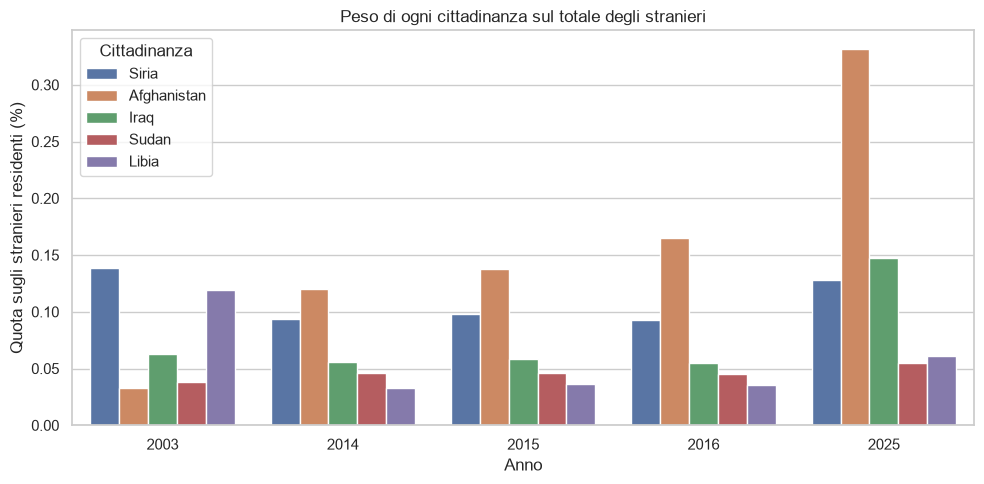

In [6]:
anni_col, stati_col, quote_col = [], [], []
for a in ANNI:
    for s in STATI:
        anni_col.append(a); stati_col.append(s); quote_col.append(quote[a][s])

sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=anni_col, y=quote_col, hue=stati_col, order=ANNI, ax=ax)
ax.set_xlabel("Anno")
ax.set_ylabel("Quota sugli stranieri residenti (%)")
ax.set_title("Peso di ogni cittadinanza sul totale degli stranieri")
ax.legend(title="Cittadinanza")
plt.tight_layout()
plt.show()

'CHE MANCA DA FA?'
-> finire di sistemare e descrivere questo codice, le ultime due celle soprattutto 
-> riguardare il file dati_nascite per capire cosa può ancora essere utile
-> forse sarebbero carini dei grafici per la popolazione maschile/femminile? 